calling GenPaths.py from: .../daaps/pythonModelling/DAAPS_TOOLKIT/GenPaths.py
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/FittingTools
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel
global path variables:
	 PROJECT_PATH =.../.../vera/daaps/pythonModelling/DAAPS_TOOLKIT
	 OPTICS_DATA_PATH =.../.../daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA
	 LITERATURE_DATA_PATH =.../.../daaps/pythonModelling/DAAPS_TOOLKIT/literatureDATA
	 VERA_DATA_PATH =.../.../projects/vera/daaps/veraData
------------------------------------------------
['air', 'lxe', 'lxe2', 'cf4', 'green', 'red']
style object members: 	 ['col', 'ls', 'name', 'printMembers']


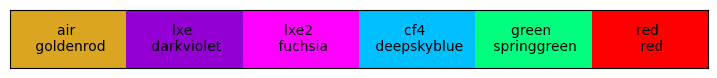

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_filter1d
import time

from scipy import optimize as opt
from scipy import stats as sps
import iminuit
from iminuit import Minuit

import json

import sys
sys.path.append('../')
from DAAPS_TOOLKIT.GenPaths import *

import PDEModel.MathEquations as ME
from PDEModel.OpticsDataLoader import *
import PDEModel.PDEStyle as MS
from PDEModel.PhotonInfo import * # this calls DataLoader when defining init
from PDEModel import PNJunction as PNJ

from cycler import cycler


MS.ShowMyStyles() # for colors
ms = MS.MyStyleSet() # object to use like
# ms.SetMPLcolors() # turn off with "off" option

rad2deg = 180/np.pi

---
### Giacomo paper curves

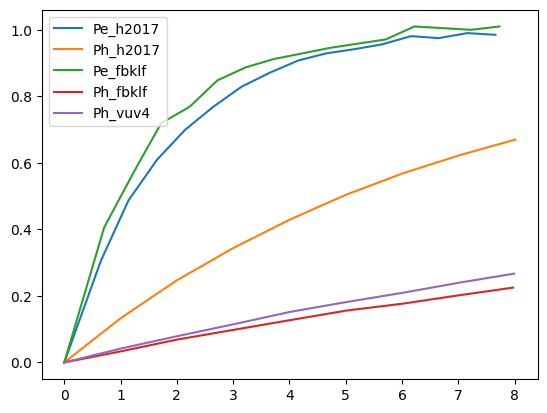

In [2]:
# ATP paper curves
pe_h2017 = np.loadtxt('outputs/giacomo_atpPaper/'+"Pe_h2017.txt", delimiter=',', unpack=True)
ph_h2017 = np.loadtxt('outputs/giacomo_atpPaper/'+"Ph_h2017.txt", delimiter=',', unpack=True)

ph_vuv4 = np.loadtxt('outputs/giacomo_atpPaper/'+"Ph_vuv4.txt", delimiter=',', unpack=True)

pe_fbklf = np.loadtxt('outputs/giacomo_atpPaper/'+"Pe_fbklf.txt", delimiter=',', unpack=True)
ph_fbklf = np.loadtxt('outputs/giacomo_atpPaper/'+"Ph_fbklf.txt", delimiter=',', unpack=True)

plt.plot(pe_h2017[0], pe_h2017[1], label='Pe_h2017')
plt.plot(ph_h2017[0], ph_h2017[1], label='Ph_h2017')
plt.plot(pe_fbklf[0], pe_fbklf[1], label='Pe_fbklf')
plt.plot(ph_fbklf[0], ph_fbklf[1], label='Ph_fbklf')
plt.plot(ph_vuv4[0], ph_vuv4[1], label='Ph_vuv4')

plt.legend()


---- Harry Pe values ----
{1: 0.486306, 2: 0.733673, 3: 0.858569, 4: 0.925484, 5: 0.961845, 6: 0.981696, 7: 0.993065, 8: 0.997103, 9: 1.0}


Text(0, 0.5, 'Pe')

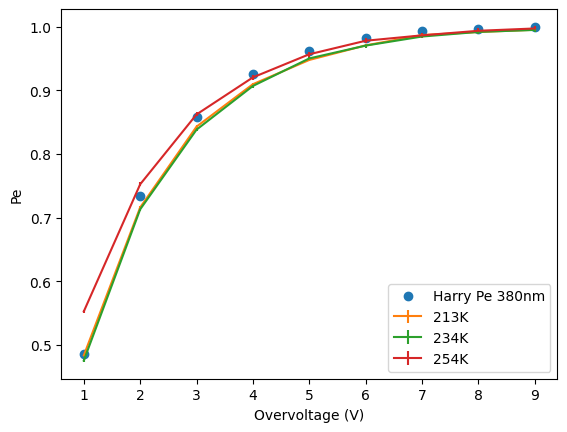

In [3]:
## Harry's 380~nm PE data
## 213K
overvoltage_213k = [1, 2, 3, 4, 5, 6, 7, 8, 9]
pa_213k = [0.483472, 0.716106, 0.843067, 0.909759, 0.947856, 0.970744, 0.986914, 0.991769, 0.995295]
pa_error_213k = [0.00141454, 0.00177954, 0.00201053, 0.00214232, 0.00222166, 0.00227794, 0.00232136, 0.002344, 0.00236474]

## 234K
overvoltage_234k = [1, 2, 3, 4, 5, 6, 7, 8, 9]
pa_234k = [0.475454, 0.713112, 0.838329, 0.906976, 0.95025, 0.970392, 0.984652, 0.991921, 0.995033]
pa_error_234k = [0.00221301, 0.00242933, 0.0026546, 0.00280772, 0.00292199, 0.00299275, 0.00305944, 0.00311978, 0.003172]

## -20
overvoltage_254k = [1, 2, 3, 4, 5, 6, 7, 8, 9]
pa_254k = [0.552663, 0.752471, 0.862244, 0.920471, 0.956795, 0.978047, 0.986519, 0.993679, 0.997341]
pa_error_254k = [0.00249031, 0.00291201, 0.0032007, 0.00339486, 0.00355269, 0.00367885, 0.00378663, 0.00389088, 0.00399673]

## 160 K (used in PDE paper)
file_path_pe = os.path.join(VERA_DATA_PATH, "HPK_EHPAIR_183K.csv")
df_pe = pd.read_csv(file_path_pe, header=0)

# print(df_pe)
df_pe=df_pe[df_pe['Wavelength'] == 380]
# print(df_pe)

harryPe = df_pe['normalized rate'].values
harryErrorPe = df_pe['Error'].values/df_pe['Raw rate'].values
harryVoltagePE = df_pe['Overvoltage'].values
harryPedict = {df_pe["Overvoltage"].values[i]: harryPe[i] for i in range(len(harryPe))}

print("---- Harry Pe values ----")
print(harryPedict)

plt.plot(harryVoltagePE, harryPe, 'o', label='Harry Pe 380nm')
plt.errorbar(overvoltage_213k, pa_213k, yerr=pa_error_213k, fmt='', label='213K')
plt.errorbar(overvoltage_234k, pa_234k, yerr=pa_error_234k, fmt='', label='234K')
plt.errorbar(overvoltage_254k, pa_254k, yerr=pa_error_254k, fmt='', label='254K')
plt.xlabel('Overvoltage (V)')

plt.legend()
plt.ylabel('Pe')

In [4]:
##### Parameterized fit curves #####
## load in new json data
# with open("fit_results.json", 'r') as file:
#     json_fits = json.load(file)
    
## default global fit result
# jsondefault_global = json_fits["HPK_VUV4"]["default_global"]
# ve_vuv_defg = json_fits["HPK_VUV4"]["default_global"]["fit_parameters"]["Ve"]
# vh_vuv_defg = json_fits["HPK_VUV4"]["default_global"]["fit_parameters"]["Vh"]
ve_vuv_defg = 1.8
vh_vuv_defg = [16.76, 1.2]

vh_vuv_frantag = [4.7, 0.3]

# ve_vuv_frantag = json_fits["HPK_VUV4"]["franta_global"]["fit_parameters"]["Ve"]
# vh_vuv_frantag = json_fits["HPK_VUV4"]["franta_global"]["fit_parameters"]["Vh"]

# ve_fbk_defg = json_fits["FBK_LF"]["default_global"]["fit_parameters"]["Ve"]
# vh_fbk_defg = json_fits["FBK_LF"]["default_global"]["fit_parameters"]["Vh"]

# ve_fbk_frantag = json_fits["FBK_LF"]["franta_global"]["fit_parameters"]["Ve"]
# vh_fbk_frantag = json_fits["FBK_LF"]["franta_global"]["fit_parameters"]["Vh"]
ve_fbk_defg = 1.87
vh_fbk_defg = [20.1, 0.26]

vh_fbk_frantag = [13.7, 0.4]

df_vuv4_def_nested = pd.read_csv("outputs/HPK_wlen_fits/HPK_Pcurves_global_nested_mar2_2026.csv", skiprows=1)
print(df_vuv4_def_nested.keys())
df_vuv4_franta_nested = pd.read_csv("outputs/HPK_wlen_fits/HPK_Pcurves_global_FRANTA_nested_mar2_2026.csv", skiprows=1)

df_fbk_def_nested = pd.read_csv("outputs/FBK_wlen_fits/FBK_Pcurves_global_default_nested_mar2_2026.csv",skiprows=1)
df_fbk_franta_nested = pd.read_csv("outputs/FBK_wlen_fits/FBK_Pcurves_global_FRANTA_nested_mar2_2026.csv",skiprows=1)


Index(['overvoltage', 'pe', 'errpe', 'ph', 'errph'], dtype='object')


---
### need to show some stuff

In [5]:
lw_franta = 4
la_franta = 0.5

ms_paper = 'd'

ms_nested = 's'

errPh_H = 0.15
errPh_VUV4 = 0.73
errPh_FBKL = 0.19

max dif
[1 2 3 4 5 6 7 8 9]
[0.28644122 0.1357338  0.07618382 0.04242424 0.02731721 0.01905617
 0.01038746 0.00762532 0.00549543]


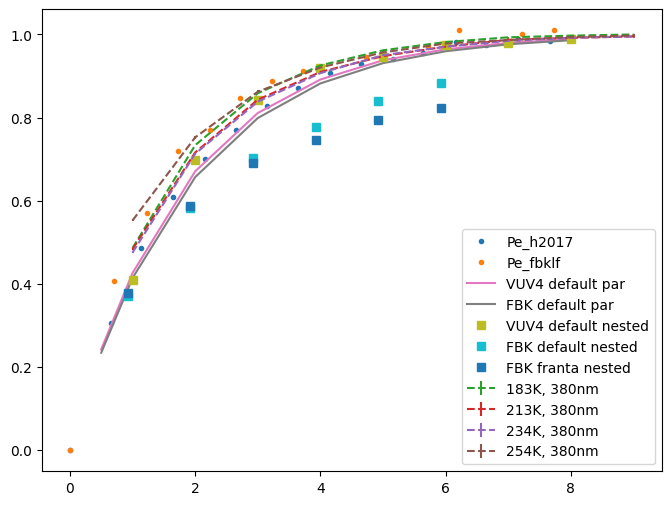

In [6]:
## compared PE curves
fig, ax = plt.subplots(1, 1, figsize=(8, 6))
x = np.append([0.5], harryVoltagePE[:-1])

# paper
# 380nm
# fits, parameterized
# fits, nested

# from paper
ax.plot(pe_h2017[0], pe_h2017[1], marker = ".", linestyle="none", label='Pe_h2017')
ax.plot(pe_fbklf[0], pe_fbklf[1], marker = ".", linestyle="none", label='Pe_fbklf')

# harry
str_toadd = ", 380nm"
ax.errorbar(harryVoltagePE, harryPe, harryPe*1e-3, linestyle="--", label='183K'+str_toadd)

plt.errorbar(overvoltage_213k, pa_213k, yerr=pa_error_213k, fmt='--', label='213K'+str_toadd)
plt.errorbar(overvoltage_234k, pa_234k, yerr=pa_error_234k, fmt='--', label='234K'+str_toadd)
overvoltage_254k = np.array(overvoltage_254k)
plt.errorbar(overvoltage_254k, pa_254k, yerr=pa_error_254k, fmt='--', label='254K'+str_toadd)

# HPK - parameterized
ax.plot(x, ME.Pcar_parametrized(x, ve_vuv_defg, 1.0), label='VUV4 default par')
# ax.plot(x, ME.Pcar_parametrized(x, ve_vuv_frantag[0], 1.0), label='VUV4 franta par')

# fbk - parameterized
ax.plot(x, ME.Pcar_parametrized(x, ve_fbk_defg, 1.0), label='FBK default par')
# ax.plot(x, ME.Pcar_parametrized(x, ve_fbk_frantag[0], 1.0), label='FBK franta par')

# #HPK - nested
ax.plot(df_vuv4_def_nested['overvoltage'].values, df_vuv4_def_nested['pe'].values, marker = "s", linestyle = "None", label='VUV4 default nested')
# ax.plot(df_vuv4_franta_nested['overvoltage'].values, df_vuv4_franta_nested['pe'].values, label='VUV4 franta global nested') ## ignore for bad Ph values

# # # FBK - nested
ax.plot(df_fbk_def_nested['overvoltage'].values, df_fbk_def_nested['pe'].values, marker = "s", linestyle = "None", label='FBK default nested')
ax.plot(df_fbk_franta_nested['overvoltage'].values, df_fbk_franta_nested['pe'].values, marker = "s", linestyle = "None", label='FBK franta nested')

# ax.set_xscale('log')
# ax.set_ylim(0.8, 1.05)
ax.legend()

# percent difference

maxDif = (pa_254k - ME.Pcar_parametrized(overvoltage_254k, ve_fbk_defg, 1.0)) / ((pa_254k + ME.Pcar_parametrized(overvoltage_254k, ve_fbk_defg, 1.0))/2)

print("max dif")
print(harryVoltagePE)
print(maxDif)

<ValueView eta=1.8279873366239476 Ve=2.2>
┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 0.005069                   │              Nfcn = 13               │
│ EDM = 1.22e-07 (Goal: 0.0002)    │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬──────┬───────────┬───────────┬──────────

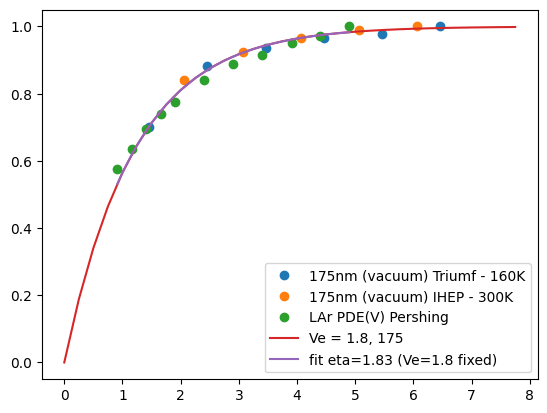

In [7]:
## load in VUV PDE(V) data which should match Pe(V)

tri_v, tri_pde, ihep_v, ihep_pde = np.loadtxt(os.path.join(LITERATURE_DATA_PATH, "nexo_gallina_performanceNovel", "VUV4_pdeVoltage.csv"), delimiter=",", skiprows=2, unpack=True)
ihep_v = ihep_v[:-1]
ihep_pde = ihep_pde[:-1]

tri_pde = tri_pde/np.max(tri_pde)  # convert to fraction
ihep_pde = ihep_pde/np.max(ihep_pde)

pershing_v, pershing_pde = np.loadtxt(os.path.join(LITERATURE_DATA_PATH,  "pershing_vuvPDE_voltage.csv"), delimiter=",", skiprows=1, unpack=True)
pershing_pde = pershing_pde/np.max(pershing_pde)
# pershing_v *= 0.8

hShift = 0.
plt.plot(tri_v + hShift, tri_pde, label='175nm (vacuum) Triumf - 160K', marker='o', linestyle='None')
plt.plot(ihep_v + hShift, ihep_pde, label='175nm (vacuum) IHEP - 300K', marker='o', linestyle='None')
plt.plot(pershing_v + hShift, pershing_pde, label='LAr PDE(V) Pershing', marker='o', linestyle='None')

# ME.QuantumPe(wlen, pe, 300, 0.75)

def quantumPE_wrapper(volt, wlen, Ve):
  Pe = ME.Pcar_parametrized(volt, Ve, 1.0)
  Qpe = ME.QuantumPe(wlen, Pe, 300, 0.75)
  return Qpe

def quantumPE_toFit(volt, eta, Ve):
  Pe = ME.Pcar_parametrized(volt, Ve, 1.0)
  Qpe = 1-(1 - Pe)**eta
  return Qpe

xtVoltages = np.arange(0, 8, 0.25)
# plt.plot(xtVoltages, ME.Pcar_parametrized(xtVoltages, 1.8, 1.0), linestyle = "-", label='Ve = 1.8')
# plt.plot(xtVoltages, ME.Pcar_parametrized(xtVoltages, 1.6, 1.0), linestyle = "-", label='Ve = 1.6')
# plt.plot(xtVoltages, ME.Pcar_parametrized(xtVoltages, 1.2, 1.0), linestyle = "-", label='Ve = 1.2')
plt.plot(xtVoltages, quantumPE_wrapper(xtVoltages, 175, 1.8), linestyle = "-", label='Ve = 1.8, 175')
# plt.plot(xtVoltages, quantumPE_wrapper(xtVoltages, 128, 1.8), linestyle = "-", label='Ve = 1.8, 128')

# --- concise iminuit fit: fit only eta, fix Ve ---
chisq = lambda eta, Ve: np.sum((quantumPE_toFit(pershing_v, eta, Ve) - pershing_pde)**2)
m = Minuit(chisq, eta=1.8, Ve=2.2);
m.errordef = Minuit.LEAST_SQUARES;
m.limits['eta']=(1.0, 3.0)
m.fixed['Ve']=True;
# m.limits['Ve'] = (1.2, 2.5)
res = m.migrad()
print(res.values)
print(res)
m.hesse()

eta_fit = m.values['eta']
print("fitted eta:", eta_fit)
vfit = np.linspace(pershing_v.min(), pershing_v.max(), 200)

plt.plot(vfit, quantumPE_toFit(vfit, eta_fit, m.values['Ve']), '-', label=f'fit eta={eta_fit:.2f} (Ve=1.8 fixed)')

plt.legend()

-- Lei paper fit - digitized --
Vc = 1.734 ± 0.078
[0.         0.49406433 0.73082086 0.85328407 0.9128245  0.95003745
 0.97143852 0.98487739 0.99615724]
[0.         0.49060937 0.73286661 0.85603239 0.92180364 0.95893616
 0.97829063 0.98915744 0.99379866 0.99623366]
-- Lei paper fit - ROOT data --
Vc = 1.516 ± 0.011


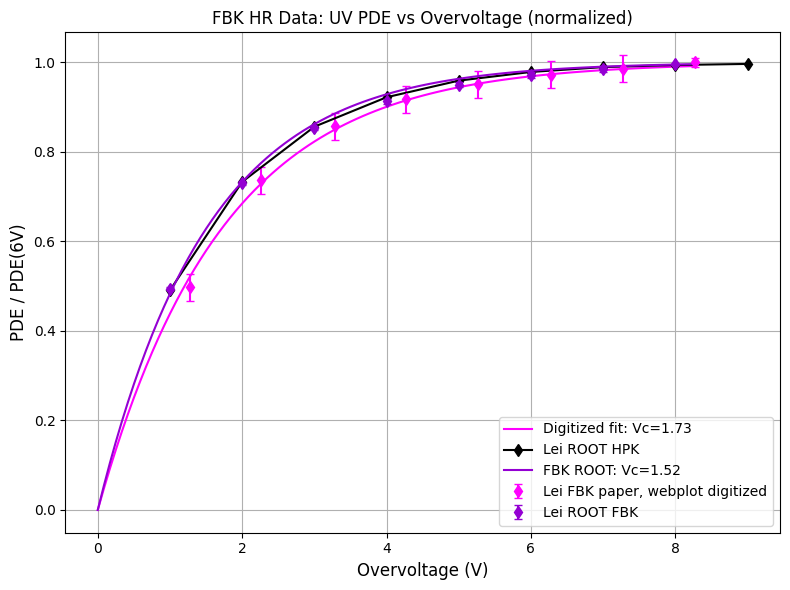

In [8]:
## Load and fit Pe data from Lei paper
from iminuit import Minuit
import uproot

fig, (ax_lei) = plt.subplots(1, 1, figsize=(8, 6))

c1 = ms.lxe2.col
c2 = ms.lxe.col

## Lei webplot digitized
xV_pe, yV_pe = np.loadtxt(os.path.join(VERA_DATA_PATH, "PE_vsV", "Pe_fbk_m60C_leiPaper.csv"), delimiter=",", skiprows=1, unpack=True)
mask = xV_pe > 0.5
xV_pe = xV_pe[mask]
yV_pe = yV_pe[mask]
yErr_pe = 0.03 * np.ones_like(yV_pe)  # 3% error on all points
yErr_pe[-1] = 0.01  # 3% error, 0.1% on highest V

chisq = lambda Vc: np.sum(((ME.Pcar_parametrized(xV_pe, Vc, 1.0) - yV_pe) / yErr_pe)**2)
m = Minuit(chisq, Vc=1.9); m.migrad()
print("-- Lei paper fit - digitized --")
print(f"Vc = {m.values['Vc']:.3f} ± {m.errors['Vc']:.3f}")

ax_lei.errorbar(xV_pe, yV_pe, yerr=yErr_pe, marker='d', color = c1, linestyle = "None", label='Lei FBK paper, webplot digitized', capsize=3)
xfit = np.linspace(0, max(xV_pe), 100)
ax_lei.plot(xfit, ME.Pcar_parametrized(xfit, m.values['Vc'], 1.0), color = c1, linestyle = "-", label=f"Digitized fit: Vc={m.values['Vc']:.2f}")

## Lei ROOT
fbkPath = "EH_Pair_PulseAnalysis_Output_FBK_R8_163K.root"
hpkPath = "lei_EH_Pair_PulseAnalysis_Output_HPK_R8_163K.root"
root160HPK = uproot.open(os.path.join(VERA_DATA_PATH, "PE_vsV", hpkPath))
plt.plot(root160HPK["Pe_Values"].member("fX")[1:], root160HPK["Pe_Values"].member("fY")[1:], marker='d', color = "k", linestyle = "-", label="Lei ROOT HPK")

root160 = uproot.open(os.path.join(VERA_DATA_PATH, "PE_vsV", fbkPath))

print(root160["Pe_Values"].member("fY"))
print(root160HPK["Pe_Values"].member("fY"))

gerr_160 = root160["Pe_Values"]
x160_root = gerr_160.member("fX")[1:]
y160_root = gerr_160.member("fY")[1:]
yerr160_root = gerr_160.member("fEY")[1:]

chisq_root = lambda Vc: np.sum(((ME.Pcar_parametrized(x160_root[:-1], Vc, 1.0) - y160_root[:-1]) / yerr160_root[:-1])**2)
m_root = Minuit(chisq_root, Vc=1.4); m_root.migrad()
print("-- Lei paper fit - ROOT data --")
print(f"Vc = {m_root.values['Vc']:.3f} ± {m_root.errors['Vc']:.3f}")

plt.errorbar(x160_root, y160_root, yerr=yerr160_root, color = c2, marker='d', linestyle = "None", label='Lei ROOT FBK', capsize=3)
plt.plot(xfit, ME.Pcar_parametrized(xfit, m_root.values['Vc'], 1.0), color = c2, linestyle = "-", label=f"FBK ROOT: Vc={m_root.values['Vc']:.2f}")

### plotting the data ###
# target_wlens = [350, 380, 400]
target_wlens = [380]
buffer = 1  # nm
vShift = 0.075

###### formatting ######
ax_lei.set_title("Lei Paper Pe Data")

ax_lei.set_xlabel("Overvoltage (V)", fontsize=12)
ax_lei.set_ylabel("PDE / PDE(6V)", fontsize=12)
ax_lei.set_title("FBK HR Data: UV PDE vs Overvoltage (normalized)")
ax_lei.legend(loc = "lower right")
ax_lei.grid()

# ax_lei.hlines(0.88, xmin = 1, xmax = 6.2)

# ax_lei.set_xscale('log')
plt.tight_layout()
plt.show()

/var/folders/1y/pq_0h029381_cwg2wmchsdt00000gn/T/ipykernel_33940/1542225685.py:256: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


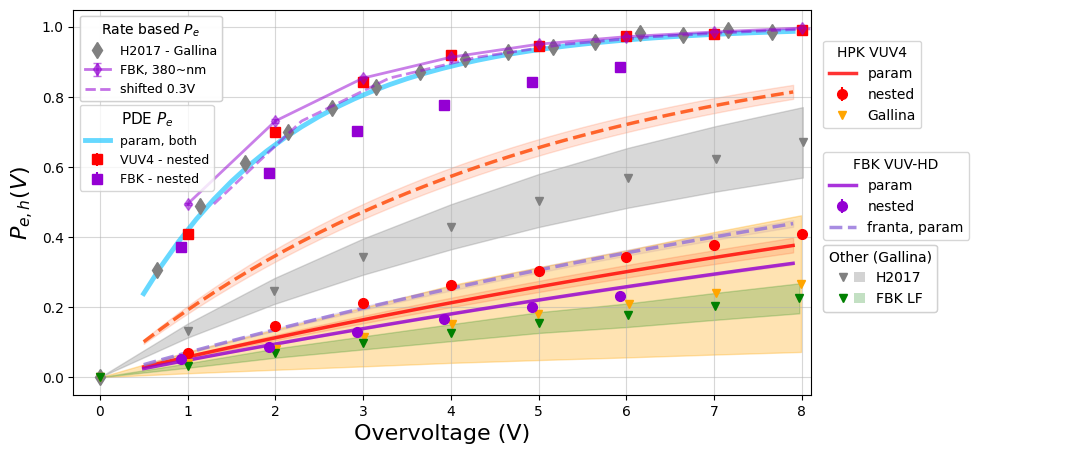

In [9]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.legend_handler import HandlerTuple
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(13, 5))
gs = gridspec.GridSpec(1, 2, width_ratios=[3, 1], wspace=0.05)

ax = fig.add_subplot(gs[0])
legAx = fig.add_subplot(gs[1])
legAx.axis('off')

# --- Style definitions ---
parLine = "-"       # parameterized curves
nestedMarker = "s"  # nested fit data points
inputMarker = "d"   # input/literature data

# Colors: VUV4 = warm (red/orange), FBK = cold (purple/blue)
vuv4Col = ms.red.col
fbkCol = ms.lxe.col

bothCol = ms.cf4.col

x = np.append([0.5], harryVoltagePE[:-1])
x = np.arange(min(x), max(x), 0.2)

######### Pe curves - ALL DATA #########

### === Pe PARAMETERIZED CURVES (solid lines) === ###
# VUV4 parameterized (default)
h_pe_vuv4_par, = ax.plot(x, ME.Pcar_parametrized(x, (ve_vuv_defg+ve_fbk_defg)/2, 1.0), 
                         linewidth=3.5, alpha = 0.6, linestyle=parLine, color=bothCol, 
                         label='param, both')

# FBK parameterized (default)
# h_pe_fbk_par, = ax.plot(x, ME.Pcar_parametrized(x, ve_fbk_defg, 1.0), 
#                         linewidth=2.5, linestyle=parLine, alpha = 0.6, color=fbkCol, 
#                         label='Param - FBK')

### === Pe NESTED FIT DATA (square markers) === ###
# VUV4 nested
h_pe_vuv4_nested = ax.errorbar(df_vuv4_def_nested['overvoltage'].values, 
                               df_vuv4_def_nested['pe'].values, 
                               yerr=df_vuv4_def_nested['errpe'].values,
                               marker=nestedMarker, markersize=7, linestyle="None", 
                               color=vuv4Col, label='VUV4 - nested')

# # VUV4 Franta nested
# h_pe_vuv4_franta_nested = ax.errorbar(df_vuv4_franta_nested['overvoltage'].values, 
#                                       df_vuv4_franta_nested['pe'].values, 
#                                       yerr=df_vuv4_franta_nested['errpe'].values,
#                                       marker="^", markersize=7, linestyle="None", 
#                                       color="orangered", alpha=0.7, label='VUV4 nested (Franta)')

# FBK nested (default)
h_pe_fbk_nested = ax.errorbar(df_fbk_def_nested['overvoltage'].values, 
                              df_fbk_def_nested['pe'].values, 
                              yerr=df_fbk_def_nested['errpe'].values,
                              marker=nestedMarker, markersize=7, linestyle="None", 
                              color=fbkCol, label='FBK - nested')


# # FBK Franta nested
# h_pe_fbk_franta_nested = ax.errorbar(df_fbk_franta_nested['overvoltage'].values, 
#                                      df_fbk_franta_nested['pe'].values, 
#                                      yerr=df_fbk_franta_nested['errpe'].values,
#                                      marker="v", markersize=7, linestyle="None", 
#                                      color="mediumpurple", alpha=0.7, label='FBK nested (Franta)')

### === Pe INPUT/LITERATURE DATA (diamond markers, dashed lines) === ###
# Giacomo paper curves
h_pe_h2017, = ax.plot(pe_h2017[0], pe_h2017[1], marker=inputMarker, markersize=8,
                      linestyle="None", linewidth=1, color="gray", alpha=1.,
                      label='H2017 - Gallina')

# h_pe_fbklf, = ax.plot(pe_fbklf[0], pe_fbklf[1], marker=inputMarker, markersize=5,
#                       linestyle="--", linewidth=1, color="green", alpha=0.8,
#                       label='FBK LF - Gallina')

# Harry's 380nm data (various temperatures)
vshift = 0.3
fbk_Lei = ax.errorbar(x160_root, y160_root, yerr=yerr160_root, color = c2, marker='d',
                       linestyle = "-", linewidth = 2, alpha = 0.5, label='FBK, 380~nm', capsize=3)

fbk_Lei_shifted, = ax.plot(x160_root+vshift, y160_root, color = c2, marker='None',
                       linestyle = "--", linewidth = 2, alpha = 0.5, label='shifted 0.3V')

# h_pe_183k = ax.errorbar(harryVoltagePE, harryPe, yerr=harryErrorPe, marker="P",
#                         markersize=5, linestyle=":", linewidth=1, color=vuv4Col, label='VUV4')

# h_pe_213k = ax.errorbar(overvoltage_213k, pa_213k, yerr=pa_error_213k, 
#                         marker="o", markersize=5, linestyle=":", linewidth=1,
#                         color="coral", label='213K, 380nm')

# h_pe_234k = ax.errorbar(overvoltage_234k, pa_234k, yerr=pa_error_234k, 
#                         marker="o", markersize=5, linestyle=":", linewidth=1,
#                         color="salmon", label='234K, 380nm')

# h_pe_254k = ax.errorbar(overvoltage_254k, pa_254k, yerr=pa_error_254k, 
#                         marker="o", markersize=5, linestyle=":", linewidth=1,
#                         color="lightsalmon", label='254K, 380nm')

######### Ph curves - ALL DATA #########

### === Ph PARAMETERIZED CURVES (solid lines, thinner) === ###
# VUV4 Ph parameterized
h_ph_vuv4_par, = ax.plot(x, ME.Pcar_parametrized(x, vh_vuv_defg[0], 1.0), 
                         linewidth=2.5, linestyle=parLine, color=vuv4Col, 
                         alpha=0.8, label='param')
ax.fill_between(x, ME.Pcar_parametrized(x, vh_vuv_defg[0]-vh_vuv_defg[1], 1.0),
                   ME.Pcar_parametrized(x, vh_vuv_defg[0]+vh_vuv_defg[1], 1.0),
                   alpha=0.15, edgecolor="none", color=vuv4Col)

h_ph_vuv4_franta_par, = ax.plot(x, ME.Pcar_parametrized(x, vh_vuv_frantag[0], 1.0),
                         linewidth=2.5, linestyle = "--", color="orangered",
                         alpha=0.8, label='franta, param')
ax.fill_between(x, ME.Pcar_parametrized(x, vh_vuv_frantag[0]-vh_vuv_frantag[1], 1.0),
                   ME.Pcar_parametrized(x, vh_vuv_frantag[0]+vh_vuv_frantag[1], 1.0),
                   alpha=0.15, edgecolor="none", color="orangered")

# FBK Ph parameterized
h_ph_fbk_par, = ax.plot(x, ME.Pcar_parametrized(x, vh_fbk_defg[0], 1.0), 
                        linewidth=2.5, linestyle=parLine, color=fbkCol, 
                        alpha=0.8, label='param')
ax.fill_between(x, ME.Pcar_parametrized(x, vh_fbk_defg[0]-vh_fbk_defg[1], 1.0),
                   ME.Pcar_parametrized(x, vh_fbk_defg[0]+vh_fbk_defg[1], 1.0),
                   alpha=0.15, edgecolor="none", color=fbkCol)

h_ph_fbk_franta_par, = ax.plot(x, ME.Pcar_parametrized(x, vh_fbk_frantag[0], 1.0), 
                        linewidth=2.5, linestyle = "--", color="mediumpurple", 
                        alpha=0.8, label='franta, param')
ax.fill_between(x, ME.Pcar_parametrized(x, vh_fbk_frantag[0]-vh_fbk_frantag[1], 1.0),
                   ME.Pcar_parametrized(x, vh_fbk_frantag[0]+vh_fbk_frantag[1], 1.0),
                   alpha=0.15, edgecolor="none", color="mediumpurple")

# h_ph_fbk_franta_par = ax.plot(x, ME.Pcar_parametrized(x, vh_fbk_frantag[0], 1.0),
#                         linewidth=2.5, linestyle=parLine, color="mediumpurple",
#                         alpha=0.8, label='FBK franta par')

### === Ph NESTED FIT DATA (square markers, smaller) === ###
# VUV4 Ph nested
h_ph_vuv4_nested = ax.errorbar(df_vuv4_def_nested['overvoltage'].values, 
                               df_vuv4_def_nested['ph'].values, 
                               yerr=df_vuv4_def_nested['errph'].values,
                               marker="o", markersize=7, linestyle="None", 
                               color=vuv4Col, alpha=1.0, label='nested')

# VUV4 Ph Franta nested
# h_ph_vuv4_franta_nested = ax.errorbar(df_vuv4_franta_nested['overvoltage'].values, 
#                                       df_vuv4_franta_nested['ph'].values, 
#                                       yerr=df_vuv4_franta_nested['errph'].values,
#                                       marker="^", markersize=5, linestyle="None", 
#                                       color="orangered", alpha=0.5, label='VUV4 Ph nested (Franta)')

# FBK Ph nested
h_ph_fbk_nested = ax.errorbar(df_fbk_def_nested['overvoltage'].values, 
                              df_fbk_def_nested['ph'].values, 
                              yerr=df_fbk_def_nested['errph'].values,
                              marker="o", markersize=7, linestyle="None", 
                              color=fbkCol, alpha=1.0, label='nested')

# FBK Ph Franta nested  
# h_ph_fbk_franta_nested = ax.errorbar(df_fbk_franta_nested['overvoltage'].values, 
#                                      df_fbk_franta_nested['ph'].values, 
#                                      yerr=df_fbk_franta_nested['errph'].values,
#                                      marker="X", markersize=6, linestyle="None", 
#                                      color=fbkCol, alpha=1.0, label='nested (Franta)')

### === Ph INPUT/LITERATURE DATA (Giacomo paper) === ###
# Ph from Giacomo paper - H2017
h_ph_h2017, = ax.plot(ph_h2017[0], ph_h2017[1], marker="v", markersize=6,
                      linestyle="None", linewidth=1, color="gray", alpha=1.0,
                      label='H2017')
ax.fill_between(ph_h2017[0], ph_h2017[1]*(1-errPh_H), ph_h2017[1]*(1+errPh_H), 
                alpha=0.3, edgecolor="none", color="gray")

# Ph from Giacomo paper - VUV4
h_ph_vuv4_gallina, = ax.plot(ph_vuv4[0], ph_vuv4[1], marker="v", markersize=6,
                             linestyle="None", linewidth=1, color="orange", alpha=1.0,
                             label='Gallina')
ax.fill_between(ph_vuv4[0], ph_vuv4[1]*(1-errPh_VUV4), ph_vuv4[1]*(1+errPh_VUV4), 
                alpha=0.3, edgecolor="none", color="orange")

# Ph from Giacomo paper - FBK LF
h_ph_fbklf, = ax.plot(ph_fbklf[0], ph_fbklf[1], marker="v", markersize=6,
                      linestyle="None", linewidth=1, color="green", alpha=1.0,
                      label='FBK LF')
ax.fill_between(ph_fbklf[0], ph_fbklf[1]*(1-errPh_FBKL), ph_fbklf[1]*(1+errPh_FBKL), 
                alpha=0.2, edgecolor="none", color="green")

### === LEGEND ORGANIZATION === ###

# Pe legend handles - fit-based
pe_all_handles = [h_pe_vuv4_par, h_pe_vuv4_nested, h_pe_fbk_nested] #h_pe_fbk_par

# Pe legend handles - rate-based
pe_rate_handles = [h_pe_h2017, fbk_Lei, fbk_Lei_shifted]

# Patch handles for Gallina fill_between shading in legend
patch_h2017 = Patch(facecolor='gray', alpha=0.3, edgecolor='none')
patch_vuv4_gallina = Patch(facecolor='orange', alpha=0.3, edgecolor='none')
patch_fbklf = Patch(facecolor='green', alpha=0.2, edgecolor='none')

# Ph legend handles - grouped by device
ph_vuv4_handles = [h_ph_vuv4_par, h_ph_vuv4_nested, h_ph_vuv4_gallina]
ph_fbk_handles = [h_ph_fbk_par, h_ph_fbk_nested, h_ph_fbk_franta_par] #h_ph_fbk_franta_nested
ph_other_handles = [(h_ph_h2017, patch_h2017), (h_ph_fbklf, patch_fbklf)]

# Pe legend on plot (top left corner) - fit-based
legend_pe = ax.legend(handles=pe_all_handles, labels=[h.get_label() for h in pe_all_handles], 
                      loc='upper left', title=r"PDE $P_e$", fontsize=9, title_fontsize=11,
                      ncol=1, frameon=True, framealpha=0.8, borderaxespad=0.5,
                      bbox_to_anchor=(-0.0, 0.77))
ax.add_artist(legend_pe)

# Pe legend - rate-based (below the first)
legend_pe_rate = ax.legend(handles=pe_rate_handles, labels=[h.get_label() for h in pe_rate_handles], 
                           loc='upper left', title=r"Rate based $P_e$", fontsize=9, title_fontsize=10,
                           ncol=1, frameon=True, framealpha=0.8, borderaxespad=0.5,
                           bbox_to_anchor=(-0.0, 1.0))
ax.add_artist(legend_pe_rate)

xSpot2 = -0.05  # x position for Ph legends on the legend panel
# Ph legends (on legend panel) - grouped by device
legend_ph_vuv4 = legAx.legend(handles=ph_vuv4_handles, 
                               labels=[h.get_label() for h in ph_vuv4_handles], 
                               loc='upper left', title="HPK VUV4", title_fontsize=10, fontsize=10, 
                               ncol=1, frameon=True, borderaxespad=0., 
                               handler_map={tuple: HandlerTuple(ndivide=None)},
                               bbox_to_anchor=(xSpot2, 0.92), bbox_transform=legAx.transData)

legend_ph_fbk = legAx.legend(handles=ph_fbk_handles, labels=[h.get_label() for h in ph_fbk_handles], 
                              loc='upper left', title="FBK VUV-HD", title_fontsize=10, fontsize=10, 
                              ncol=1, frameon=True, borderaxespad=0., 
                              bbox_to_anchor=(xSpot2, 0.63), bbox_transform=legAx.transData)

legend_ph_other = legAx.legend(handles=ph_other_handles, 
                               labels=[h.get_label() if not isinstance(h, tuple) else h[0].get_label() for h in ph_other_handles], 
                               loc='upper left', title="Other (Gallina)", title_fontsize=10, fontsize=10, 
                               ncol=1, frameon=True, borderaxespad=0., 
                               handler_map={tuple: HandlerTuple(ndivide=None)},
                               bbox_to_anchor=(xSpot2, 0.39), bbox_transform=legAx.transData)

legAx.add_artist(legend_ph_vuv4)
legAx.add_artist(legend_ph_fbk)
legAx.add_artist(legend_ph_other)

### === FORMATTING === ###
ax.set_xlabel('Overvoltage (V)', fontsize=16)
ax.set_ylabel(r'$P_{e,h}(V)$', fontsize=16)
# ax.set_title(r'All $P_e$ and $P_h$ Data Comparison', fontsize=14)
ax.set_xlim(-0.3, 8.1)
# ax.set_ylim(0, 1.05)
ax.grid(alpha=0.5)

plt.tight_layout()

### New Exponential Avalanche Model

We will fit the Lei FBK data (`x160_root`, `y160_root`) using a new avalanche probability function:

$$P(V) = 1 - \frac{k_1^2}{V + V_{br}} \cdot \exp\left(\frac{k_2}{V + V_{br}}\right)$$

Where:
- $k_1$ and $k_2$ are free parameters to be fitted
- $V_{br} = 40$ V (fixed breakdown voltage)
- $V$ is the overvoltage

This model incorporates both power-law and exponential dependencies on the effective voltage $(V + V_{br})$.

=== Exponential Avalanche Model Fit Results ===
k1 = 5.557253e-02 ± 1.190983e-02
k2 = 21056.7204 ± 726.8124
Chi-squared = 0.13
Reduced chi-squared = 0.02


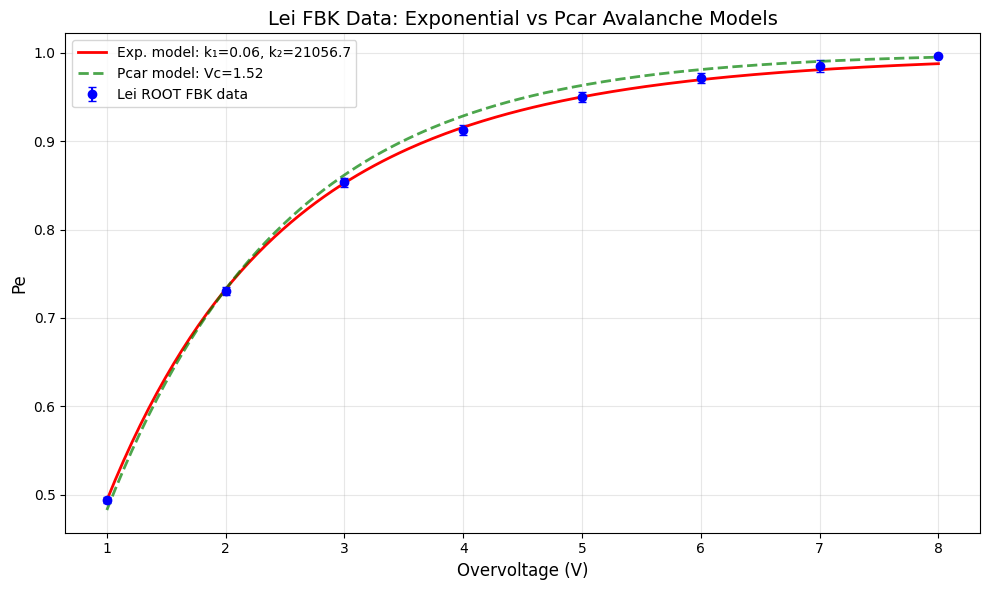


Function form:
P(V) = 1 - k₁²/(V+40) × exp(k₂/(V+40))
P(V) = 1 - 0.06²/(V+40) × exp(21056.7/(V+40))


In [15]:
## Fit Lei data with new exponential avalanche model
from iminuit import Minuit
import numpy as np

# Define the new avalanche function
def exponential_avalanche(V, k1, k2, Vbr=40.0):
    """
    New exponential avalanche model:
    P(V) = 1 - k1^2/(V+Vbr) * exp(k2/(V+Vbr))
    
    Parameters:
    V: overvoltage (array)
    k1, k2: free parameters
    Vbr: breakdown voltage (fixed at 40V)
    """
    effective_V = V + Vbr
    return 1 - (k1 / effective_V)**2 * np.exp(k2 / effective_V**2)

fixedErr = 0.03
newLeiError = fixedErr * y160_root
# Chi-squared function for fitting
def chi_squared_exp(k1, k2, Vbr = 40):
    predicted = exponential_avalanche(x160_root, k1, k2)
    return np.sum(((predicted - y160_root) / newLeiError)**2)


# Set up and run the fit
m_exp = Minuit(chi_squared_exp, k1=0.1, k2=1e3, Vbr = 40.0)

m_exp.errordef = Minuit.LEAST_SQUARES
# Set reasonable parameter limits
m_exp.limits['k1'] = (1e-5, 1e2)
m_exp.limits['k2'] = (0.001, 1e7)
m_exp.fixed['Vbr'] = True  # Fix Vbr at 40V

# Run the fit
result_exp = m_exp.migrad()
print("=== Exponential Avalanche Model Fit Results ===")
print(f"k1 = {m_exp.values['k1']:e} ± {m_exp.errors['k1']:e}")
print(f"k2 = {m_exp.values['k2']:.4f} ± {m_exp.errors['k2']:.4f}")
print(f"Chi-squared = {m_exp.fval:.2f}")
print(f"Reduced chi-squared = {m_exp.fval/(len(x160_root)-2):.2f}")

# Get uncertainties
m_exp.hesse()

# Plot the fit
fig, ax = plt.subplots(1, 1, figsize=(10, 6))

# Plot the data
ax.errorbar(x160_root, y160_root, yerr=yerr160_root, 
            marker='o', linestyle='none', color='blue', 
            label='Lei ROOT FBK data', capsize=3)

# Plot the fitted curve
V_fit = np.linspace(x160_root.min(), x160_root.max(), 200)
P_fit = exponential_avalanche(V_fit, m_exp.values['k1'], m_exp.values['k2'])

ax.plot(V_fit, P_fit, 'r-', linewidth=2, 
        label=f'Exp. model: k₁={m_exp.values["k1"]:.2f}, k₂={m_exp.values["k2"]:.1f}')

# Plot the original Pcar fit for comparison
P_pcar = ME.Pcar_parametrized(V_fit, m_root.values['Vc'], 1.0)
ax.plot(V_fit, P_pcar, 'g--', linewidth=2, alpha=0.7,
        label=f'Pcar model: Vc={m_root.values["Vc"]:.2f}')

ax.set_xlabel('Overvoltage (V)', fontsize=12)
ax.set_ylabel('Pe', fontsize=12)
ax.set_title('Lei FBK Data: Exponential vs Pcar Avalanche Models', fontsize=14)
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Print the function form for reference
print("\nFunction form:")
print("P(V) = 1 - k₁²/(V+40) × exp(k₂/(V+40))")
print(f"P(V) = 1 - {m_exp.values['k1']:.2f}²/(V+40) × exp({m_exp.values['k2']:.1f}/(V+40))")

In [16]:
hbar = 6.582119569e-16  # eV·s
e_charge = 1.602176634e-19  # C
hbar_wOpt = 63 * 1e-3  # 63 meV

eps_e = 1.37 * 1.12  # eV, pair creation energy in Si (from Biroth pdf)

def k1(reh, h_wopt):
  """
  Calculate k1 parameter for avalanche model
  
  Parameters:
  reh: dimensionless ratio
  h_wopt: hbar * optical frequency [rad/s] --> [eV]
  
  Returns:
  k1 in units of [V] (volts)
  
  Units check:
  [dimensionless] × [eV] / [C] = [eV] / [C] = [V]
  """
  return reh * h_wopt / (2 * e_charge)

def rFromk(k1, h_wopt):
  return (2 * e_charge * k1) / h_wopt

def k2(eps_eh, LambdaOpt, w, h_wopt):
  """
  Calculate k2 parameter for avalanche model
  
  Parameters:
  epsPair: pair creation energy [eV]
  LambdaOpt: optical mean free path [m]
  w: distance scale (m)
  wopt: optical frequency [rad/s]
  
  Returns:
  k2 in units of [V]^2 (volts squared)
  
  units check:
  [eV]x[s] × [rad/s] x [m]^2 × [eV]/ [C] / [m²] /[C] = [eV]^2 / [C]^2 = [V]^2
  """
  return 3/2 * h_wopt * w**2 * eps_eh / e_charge / LambdaOpt**2 / e_charge

print("estimate k2:", k2(eps_eh = eps_e, LambdaOpt = 1, w = 1, h_wopt = hbar_wOpt))

print("r1 from fit k1:", rFromk(k1 = m_exp.values['k1'], h_wopt = hbar_wOpt))

estimate k2: 5.64871431650195e+36
r1 from fit k1: 2.826571538507316e-19
